<a href="https://colab.research.google.com/github/snehal-thakor1985/myprofile/blob/main/flood_prediction_AI_agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip -q install pandas numpy scikit-learn matplotlib google-genai

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
np.random.seed(42)

n = 1000

data = pd.DataFrame({
    "rainfall": np.random.randint(0, 300, n),
    "river_level": np.random.uniform(0, 10, n),
    "soil_moisture": np.random.uniform(0, 100, n),
    "drainage_load": np.random.uniform(0, 100, n),
    "elevation": np.random.uniform(0, 100, n),
    "population_density": np.random.uniform(100, 10000, n)
})

# Generate sample flood-risk labels
risk_score = (
    data["rainfall"] * 0.30 +
    data["river_level"] * 8 +
    data["soil_moisture"] * 0.15 +
    data["drainage_load"] * 0.15 -
    data["elevation"] * 0.20
)

data["flood_risk"] = np.where(
    risk_score > 85, 1, 0
)

print(data.head())

print("\nDataset created successfully!")

   rainfall  river_level  soil_moisture  drainage_load  elevation  \
0       102     6.249760      63.607076      83.981616  64.823590   
1       270     3.777259      22.106337      75.177217  23.148010   
2       106     8.365648      97.839728      22.869441  68.135301   
3        71     5.874536      74.819191      95.632009  94.018319   
4       188     2.940447      55.781323      14.817793   4.678584   

   population_density  flood_risk  
0         6369.305696           1  
1         4557.796590           1  
2         5357.984014           1  
3         7482.604895           0  
4         8276.815099           1  

Dataset created successfully!


In [ ]:
X = data.drop("flood_risk", axis=1)
y = data["flood_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Create ML model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Test model
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Training Completed!")
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print(classification_report(y_test, y_pred))

Model Training Completed!
Model Accuracy: 92.0 %
              precision    recall  f1-score   support

           0       0.94      0.88      0.91        88
           1       0.91      0.96      0.93       112

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



In [ ]:
def disaster_ai_agent(inputs, prediction):

    rainfall = inputs["rainfall"]
    river = inputs["river_level"]
    soil = inputs["soil_moisture"]
    drainage = inputs["drainage_load"]

    print("\n========== RAKSHAK AI AGENT ==========")

    if prediction == 1:

        risk = "HIGH"

        print("Flood Risk: HIGH")
        print("\nAI Agent Recommendations:")

        if rainfall > 150:
            print("- Issue heavy rainfall alerts.")

        if river > 7:
            print("- Monitor river overflow.")

        if soil > 70:
            print("- Check waterlogging conditions.")

        if drainage > 70:
            print("- Inspect drainage systems.")

        print("- Inform local disaster management teams.")
        print("- Prepare emergency evacuation plans.")
        print("- Alert residents in vulnerable areas.")

    else:

        risk = "LOW"

        print("Flood Risk: LOW")
        print("\nAI Agent Recommendations:")
        print("- Continue regular monitoring.")
        print("- Maintain drainage infrastructure.")
        print("- Monitor rainfall and river levels.")

    print("\nAI Agent Analysis Completed.")

    return risk

In [ ]:
USE_AI = True
MODEL = "gemini-3.8-flash"

client = None

if USE_AI:
    try:
        from google.colab import userdata

        KEY = userdata.get("GEMINI_API_KEY")

        if KEY:
            from google import genai
            client = genai.Client(api_key=KEY)
            print("Gemini AI connected!")
        else:
            print("API key not found. Using Python AI agent.")

    except Exception as e:
        print("Gemini connection unavailable:", e)

Gemini AI connected!


In [ ]:
def intelligent_agent(inputs, prediction, risk):

    prompt = f"""
    You are RakshakAI, a disaster management AI assistant.

    Environmental data:
    Rainfall: {inputs['rainfall']} mm
    River level: {inputs['river_level']:.2f} m
    Soil moisture: {inputs['soil_moisture']:.2f} %
    Drainage load: {inputs['drainage_load']:.2f} %
    Elevation: {inputs['elevation']:.2f} m

    Machine Learning prediction: {risk}

    Explain:
    1. The predicted flood risk.
    2. The important environmental factors.
    3. Preventive measures.
    4. Recommendations for residents.
    5. Actions for disaster management teams.

    Mention that this is an educational prediction,
    not an official emergency warning.
    """

    if client is not None:
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt
            )

            return response.text

        except Exception as e:
            print("Gemini error:", e)

    return (
        "AI Agent Analysis:\n"
        f"Predicted flood risk: {risk}\n"
        "Follow local weather alerts and official "
        "disaster management instructions."
    )

In [ ]:
def clean_float_input(prompt):
    val = input(prompt).strip()
    # Remove '%' if present
    if val.endswith('%'):
        val = val[:-1].strip()
    return float(val)

def run_rakshak_ai():

    print("\n===== RAKSHAK AI DISASTER PREDICTION =====")

    inputs = {
        "rainfall": clean_float_input("Enter rainfall (mm): "),
        "river_level": clean_float_input("Enter river level (m): "),
        "soil_moisture": clean_float_input("Enter soil moisture (%): "),
        "drainage_load": clean_float_input("Enter drainage load (%): "),
        "elevation": clean_float_input("Enter elevation (m): "),
        "population_density": clean_float_input("Enter population density: ")
    }

    input_df = pd.DataFrame([inputs])

    # ML prediction
    prediction = model.predict(input_df)[0]

    # ML probability
    probability = model.predict_proba(input_df)[0][1]

    risk = disaster_ai_agent(inputs, prediction)

    print("\nFlood Probability:",
          round(probability * 100, 2), "%")

    print("\n========== GEMINI AI ANALYSIS ==========")

    result = intelligent_agent(inputs, prediction, risk)

    print(result)

    return risk, probability


risk, probability = run_rakshak_ai()


===== RAKSHAK AI DISASTER PREDICTION =====
Enter rainfall (mm): 220
Enter river level (m): 8.5
Enter soil moisture (%): 90
Enter drainage load (%): 15
Enter elevation (m): 95
Enter population density: 5000

========== RAKSHAK AI AGENT ==========
Flood Risk: HIGH

AI Agent Recommendations:
- Issue heavy rainfall alerts.
- Monitor river overflow.
- Check waterlogging conditions.
- Inform local disaster management teams.
- Prepare emergency evacuation plans.
- Alert residents in vulnerable areas.

AI Agent Analysis Completed.

Flood Probability: 84.0 %

========== GEMINI AI ANALYSIS ==========
Hello, I am **RakshakAI**, your disaster management AI assistant. Below is the comprehensive risk assessment and action plan based on the provided environmental parameters.

---

### 1. Predicted Flood Risk: **HIGH**
The machine learning model has evaluated the current parameters and determined a **HIGH risk of flooding**. Conditions indicate that the surrounding environment has reached a tipping p

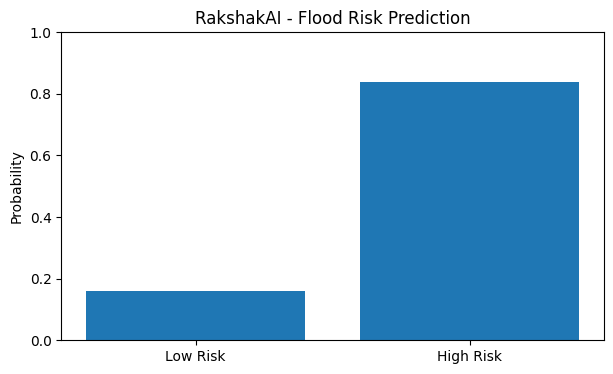

In [ ]:
plt.figure(figsize=(7, 4))

labels = ["Low Risk", "High Risk"]
values = [
    1 - probability,
    probability
]

plt.bar(labels, values)

plt.title("RakshakAI - Flood Risk Prediction")
plt.ylabel("Probability")
plt.ylim(0, 1)

plt.show()